<a href="https://colab.research.google.com/github/shreyapadte/Data-Modelling/blob/main/The_Forecasting_Horserace_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance pandas matplotlib statsmodels

In [2]:
import yfinance as yf
import pandas as pd

# iShares Euro Green Bond ETF
ticker = "GRON.DE"

data = yf.download(
    ticker,
    start="2020-01-01",
    end="2026-11-21",
    auto_adjust=True,
    progress=False
)

if data.empty:
    print("No data found. We need to verify another ticker.")
else:
    print("Download successful!")
    print("\nFirst 5 rows:")
    print(data.head())

    print("\nLast 5 rows:")
    print(data.tail())

    print("\nTotal observations:", len(data))
    print("First date:", data.index.min())
    print("Last date:", data.index.max())

Download successful!

First 5 rows:
Price          Close      High       Low      Open  Volume
Ticker       GRON.DE   GRON.DE   GRON.DE   GRON.DE GRON.DE
Date                                                      
2021-03-29  4.457159  4.472817  4.457159  4.469417    1100
2021-03-30  4.443202  4.443917  4.443202  4.443917       0
2021-03-31  4.452059  4.452059  4.443917  4.445885       0
2021-04-01  4.457787  4.457787  4.457339  4.457339       0
2021-04-06  4.461187  4.461187  4.456713  4.457966    1000

Last 5 rows:
Price          Close      High       Low      Open  Volume
Ticker       GRON.DE   GRON.DE   GRON.DE   GRON.DE GRON.DE
Date                                                      
2026-11-16  3.803313  3.809616  3.792579  3.809616    3342
2026-11-17  3.798192  3.803313  3.797208  3.797208    2718
2026-11-18  3.797700  3.807055  3.797700  3.807055    4860
2026-11-19  3.789600  3.808100  3.789600  3.808100     553
2026-11-20  3.806500  3.813900  3.798300  3.798300    1384

Total

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Extract daily closing prices
prices = data["Close"].copy()
prices.columns = ["Green_Bond_Price"]

# Calculate daily log returns (%)
returns = 100 * np.log(
    prices / prices.shift(1)
)

returns.columns = ["Green_Bond_Return"]

# Remove first missing return
returns = returns.dropna()

print("First 5 daily returns:")
print(returns.head())

print("\nSummary statistics:")
print(returns.describe())

print("\nTotal return observations:", len(returns))

First 5 daily returns:
            Green_Bond_Return
Date                         
2021-03-30          -0.313629
2021-03-31           0.199156
2021-04-01           0.128561
2021-04-06           0.076249
2021-04-07           0.164319

Summary statistics:
       Green_Bond_Return
count        1441.000000
mean           -0.010951
std             0.376516
min            -1.789266
25%            -0.225333
50%            -0.015714
75%             0.209387
max             1.799586

Total return observations: 1441


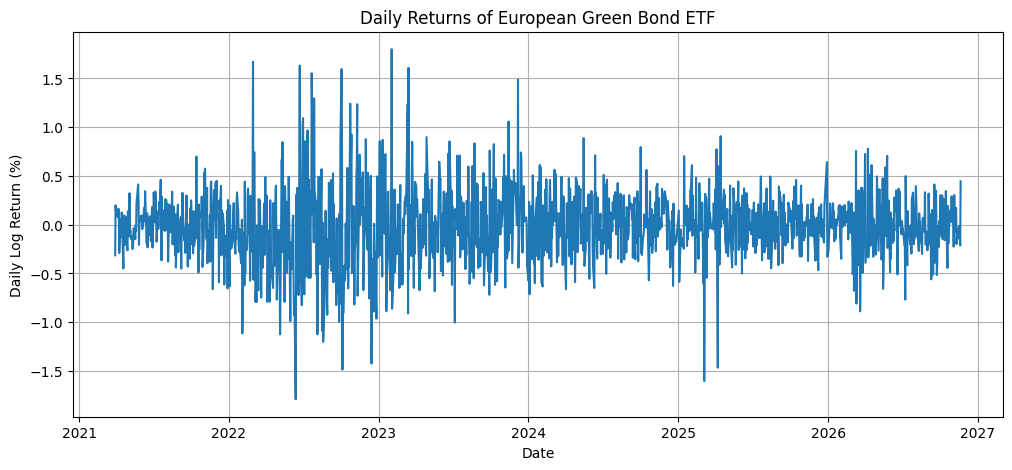

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    returns.index,
    returns["Green_Bond_Return"]
)

plt.title("Daily Returns of European Green Bond ETF")
plt.xlabel("Date")
plt.ylabel("Daily Log Return (%)")
plt.grid(True)
plt.show()

In [5]:
from statsmodels.tsa.stattools import adfuller

# Select the green bond return series
green_returns = returns["Green_Bond_Return"]

# Run Augmented Dickey-Fuller test
adf_result = adfuller(green_returns)

print("Augmented Dickey-Fuller Test")
print("---------------------------")
print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(key, ":", value)

# Interpret the result
if adf_result[1] < 0.05:
    print("\nResult: Reject the unit-root null hypothesis.")
    print("Evidence suggests the return series is stationary.")
else:
    print("\nResult: Cannot reject the unit-root null hypothesis.")
    print("There is insufficient evidence of stationarity.")

Augmented Dickey-Fuller Test
---------------------------
ADF Statistic: -8.524638835713036
P-value: 1.0774126440170687e-13

Critical Values:
1% : -3.4349700122033804
5% : -2.8635804131233096
10% : -2.567856305330816

Result: Reject the unit-root null hypothesis.
Evidence suggests the return series is stationary.


/tmp/ipykernel_1811/3914830270.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(green_returns)


In [6]:
import yfinance as yf
import numpy as np

# Conventional Euro Government Bond ETF
ticker = "EUNH.DE"

bond_data = yf.download(
    ticker,
    start="2020-01-01",
    end="2026-11-21",
    auto_adjust=True,
    progress=False
)

if bond_data.empty:
    print("Download failed.")
else:
    bond_prices = bond_data["Close"].squeeze()

    bond_returns = 100 * np.log(
        bond_prices / bond_prices.shift(1)
    )

    bond_returns = bond_returns.dropna()

    print("Download successful!")
    print("First date:", bond_returns.index.min())
    print("Last date:", bond_returns.index.max())
    print("Total observations:", len(bond_returns))
    print(bond_returns.head())

Download successful!
First date: 2020-01-03 00:00:00
Last date: 2026-11-20 00:00:00
Total observations: 1755
Date
2020-01-03    0.474691
2020-01-06   -0.080225
2020-01-07   -0.068827
2020-01-08   -0.126299
2020-01-09   -0.207008
Name: EUNH.DE, dtype: float64


In [7]:
import pandas as pd

# Combine the two return series
combined = pd.concat(
    [
        returns["Green_Bond_Return"],
        bond_returns.rename("Gov_Bond_Return")
    ],
    axis=1,
    join="inner"
).sort_index()

# Create explanatory variables using previous-day returns
combined["Lag_Green_Return"] = (
    combined["Green_Bond_Return"].shift(1)
)

combined["Lag_Gov_Return"] = (
    combined["Gov_Bond_Return"].shift(1)
)

# Remove rows with missing values
combined = combined.dropna()

# Show the completed dataset
print("First 5 observations:")
print(combined.head())

print("\nNumber of observations:", len(combined))

print("\nMissing values:")
print(combined.isna().sum())

# Save for your teammates
combined.to_csv("green_bond_ols_data.csv")

First 5 observations:
            Green_Bond_Return  Gov_Bond_Return  Lag_Green_Return  \
Date                                                               
2021-03-31           0.199156         0.132362         -0.313629   
2021-04-01           0.128561         0.226448          0.199156   
2021-04-06           0.076249        -0.226448          0.128561   
2021-04-07           0.164319        -0.018930          0.076249   
2021-04-08           0.112079         0.166182          0.164319   

            Lag_Gov_Return  
Date                        
2021-03-31       -0.226772  
2021-04-01        0.132362  
2021-04-06        0.226448  
2021-04-07       -0.226448  
2021-04-08       -0.018930  

Number of observations: 1440

Missing values:
Green_Bond_Return    0
Gov_Bond_Return      0
Lag_Green_Return     0
Lag_Gov_Return       0
dtype: int64


In [8]:
import statsmodels.api as sm

# Dependent variable
Y = combined["Green_Bond_Return"]

# Explanatory variables
X = combined[
    ["Lag_Green_Return", "Lag_Gov_Return"]
]

# Add intercept
X = sm.add_constant(X)

# Estimate OLS regression
ols_model = sm.OLS(Y, X).fit()

# Display regression results
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:      Green_Bond_Return   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     9.313
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           9.59e-05
Time:                        22:18:16   Log-Likelihood:                -627.09
No. Observations:                1440   AIC:                             1260.
Df Residuals:                    1437   BIC:                             1276.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -0.0106      0.010  

In [9]:
import statsmodels.api as sm

# Keep observations in chronological order
combined = combined.sort_index()

# Use 75% for initial training
split = int(len(combined) * 0.75)

train = combined.iloc[:split]
test = combined.iloc[split:]

# Define explanatory variables
features = ["Lag_Green_Return", "Lag_Gov_Return"]

X_train = sm.add_constant(
    train[features],
    has_constant="add"
)

Y_train = train["Green_Bond_Return"]

# Fit OLS using training data only
ols_train = sm.OLS(Y_train, X_train).fit()

print("Training observations:", len(train))
print("Evaluation observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nEvaluation period:")
print(test.index.min(), "to", test.index.max())

print("\nTraining model coefficients:")
print(ols_train.params)

Training observations: 1080
Evaluation observations: 360

Training period:
2021-03-31 00:00:00 to 2025-06-24 00:00:00

Evaluation period:
2025-06-25 00:00:00 to 2026-11-20 00:00:00

Training model coefficients:
const              -0.012915
Lag_Green_Return   -0.220722
Lag_Gov_Return      0.271507
dtype: float64


In [10]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

features = ["Lag_Green_Return", "Lag_Gov_Return"]
target = "Green_Bond_Return"

predictions = []
actual_values = []
forecast_dates = []

# Expanding-window forecasts
for i in range(len(train), len(combined)):

    # Use only observations before the forecast date
    history = combined.iloc[:i]

    X_history = sm.add_constant(
        history[features],
        has_constant="add"
    )

    y_history = history[target]

    # Re-estimate OLS
    model = sm.OLS(y_history, X_history).fit()

    # Forecast the next observation
    X_next = sm.add_constant(
        combined.iloc[[i]][features],
        has_constant="add"
    )

    forecast = model.predict(X_next).iloc[0]

    predictions.append(forecast)
    actual_values.append(combined.iloc[i][target])
    forecast_dates.append(combined.index[i])

# Store forecasting results
ols_forecasts = pd.DataFrame({
    "Actual": actual_values,
    "OLS_Forecast": predictions
}, index=forecast_dates)

ols_forecasts.index.name = "Date"

print("Number of forecasts:", len(ols_forecasts))
print(ols_forecasts.head())

# Save results
ols_forecasts.to_csv("ols_forecasts.csv")

Number of forecasts: 360
              Actual  OLS_Forecast
Date                              
2025-06-25 -0.012405     -0.042738
2025-06-26  0.014890     -0.015000
2025-06-27 -0.096789     -0.031911
2025-06-30 -0.012405      0.006023
2025-07-01  0.151347     -0.023552


In [11]:
import numpy as np
import pandas as pd

# Actual returns and OLS predictions
actual = ols_forecasts["Actual"]
ols_pred = ols_forecasts["OLS_Forecast"]

# Naive benchmark: predict zero return
naive_pred = np.zeros(len(actual))

# Define accuracy functions
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

# Calculate forecasting errors
ols_rmse = rmse(actual, ols_pred)
naive_rmse = rmse(actual, naive_pred)

ols_mae = mae(actual, ols_pred)
naive_mae = mae(actual, naive_pred)

# Relative accuracy ratios
rmse_ratio = ols_rmse / naive_rmse
mae_ratio = ols_mae / naive_mae

print("OUT-OF-SAMPLE FORECAST ACCURACY")
print("--------------------------------")
print(f"OLS RMSE: {ols_rmse:.6f}")
print(f"Naive RMSE: {naive_rmse:.6f}")

print(f"\nOLS MAE: {ols_mae:.6f}")
print(f"Naive MAE: {naive_mae:.6f}")

print(f"\nRMSE Ratio: {rmse_ratio:.4f}")
print(f"MAE Ratio: {mae_ratio:.4f}")

OUT-OF-SAMPLE FORECAST ACCURACY
--------------------------------
OLS RMSE: 0.253851
Naive RMSE: 0.254616

OLS MAE: 0.193231
Naive MAE: 0.195272

RMSE Ratio: 0.9970
MAE Ratio: 0.9895


In [12]:
import numpy as np
from scipy import stats

# Forecast errors
actual = ols_forecasts["Actual"].to_numpy()
ols = ols_forecasts["OLS_Forecast"].to_numpy()

# Squared errors
ols_loss = (actual - ols) ** 2
naive_loss = actual ** 2

# Loss differential
# Negative = OLS performs better
d = ols_loss - naive_loss

# DM test for one-step-ahead forecasts
T = len(d)
mean_d = np.mean(d)

# HAC variance estimator with 5 lags
lag = 5
gamma0 = np.mean((d - mean_d) ** 2)
long_run_var = gamma0

for k in range(1, lag + 1):
    gamma_k = np.mean(
        (d[k:] - mean_d) *
        (d[:-k] - mean_d)
    )
    weight = 1 - k / (lag + 1)
    long_run_var += 2 * weight * gamma_k

dm_stat = mean_d / np.sqrt(long_run_var / T)
p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))

print("DIEBOLD-MARIANO TEST")
print("---------------------")
print(f"DM Statistic: {dm_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Reject equal predictive accuracy.")
else:
    print("Cannot reject equal predictive accuracy.")

DIEBOLD-MARIANO TEST
---------------------
DM Statistic: -0.2484
P-value: 0.8038
Cannot reject equal predictive accuracy.


In [13]:
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)

# Use training-sample OLS residuals
residuals = ols_train.resid

# Ljung-Box test for serial correlation
lb = acorr_ljungbox(
    residuals,
    lags=[5, 10],
    return_df=True
)

print("LJUNG-BOX TEST")
print(lb)

# ARCH-LM test for conditional heteroskedasticity
arch = het_arch(residuals, nlags=5)

print("\nARCH-LM TEST")
print("LM Statistic:", arch[0])
print("P-value:", arch[1])

LJUNG-BOX TEST
      lb_stat  lb_pvalue
5    5.341123   0.375682
10  11.636496   0.310121

ARCH-LM TEST
LM Statistic: 68.82045674562559
P-value: 1.803072900059316e-13


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [14]:
import numpy as np

print("DATA QUALITY CHECK")
print("------------------")

print("Combined observations:", len(combined))
print("First date:", combined.index.min())
print("Last date:", combined.index.max())

print("\nMissing values:")
print(combined.isna().sum())

print("\nZero-return percentages:")
for col in ["Green_Bond_Return", "Gov_Bond_Return"]:
    pct = 100 * np.mean(np.isclose(combined[col], 0, atol=1e-10))
    print(f"{col}: {pct:.2f}%")

print("\nDuplicate dates:", combined.index.duplicated().sum())

print("\nExtreme returns (%):")
print(combined[
    ["Green_Bond_Return", "Gov_Bond_Return"]
].agg(["min", "max"]))

DATA QUALITY CHECK
------------------
Combined observations: 1440
First date: 2021-03-31 00:00:00
Last date: 2026-11-20 00:00:00

Missing values:
Green_Bond_Return    0
Gov_Bond_Return      0
Lag_Green_Return     0
Lag_Gov_Return       0
dtype: int64

Zero-return percentages:
Green_Bond_Return: 0.49%
Gov_Bond_Return: 0.90%

Duplicate dates: 0

Extreme returns (%):
     Green_Bond_Return  Gov_Bond_Return
min          -1.789266        -1.588707
max           1.799586         2.001091


In [15]:
# Save common return series for the whole group
group_data = combined[
    ["Green_Bond_Return", "Gov_Bond_Return"]
].copy()

group_data.to_csv("green_bond_group_data.csv")

# Save OLS regression dataset
combined.to_csv("green_bond_ols_data.csv")

# Save out-of-sample OLS forecasts
ols_forecasts.to_csv("ols_forecasts.csv")

print("All three CSV files saved successfully!")

All three CSV files saved successfully!


In [16]:
import yfinance as yf

# Download EUR/USD exchange rate
fx_data = yf.download(
    "EURUSD=X",
    start="2020-01-01",
    end="2026-11-21",
    auto_adjust=True,
    progress=False
)

print("EUR/USD observations:", len(fx_data))
print("\nFirst observations:")
print(fx_data.head())

print("\nLast observations:")
print(fx_data.tail())

EUR/USD observations: 1793

First observations:
Price          Close      High       Low      Open   Volume
Ticker      EURUSD=X  EURUSD=X  EURUSD=X  EURUSD=X EURUSD=X
Date                                                       
2020-01-01  1.122083  1.122838  1.115947  1.122083        0
2020-01-02  1.122083  1.122712  1.116682  1.121894        0
2020-01-03  1.117144  1.118068  1.112570  1.117081        0
2020-01-06  1.116196  1.120825  1.115810  1.116246        0
2020-01-07  1.119799  1.119946  1.113487  1.119583        0

Last observations:
Price          Close      High       Low      Open   Volume
Ticker      EURUSD=X  EURUSD=X  EURUSD=X  EURUSD=X EURUSD=X
Date                                                       
2026-11-16  1.102487  1.103144  1.100098  1.102621        0
2026-11-17  1.099820  1.102050  1.096960  1.099868        0
2026-11-18  1.099288  1.099747  1.095446  1.099118        0
2026-11-19  1.097201  1.101200  1.095638  1.097189        0
2026-11-20  1.096972  1.099916  

In [17]:
import numpy as np
import pandas as pd

# Extract EUR/USD closing prices
fx_prices = fx_data["Close"].squeeze()

# Calculate daily logarithmic returns (%)
fx_returns = 100 * np.log(
    fx_prices / fx_prices.shift(1)
)

fx_returns.name = "FX_Return"

# Join EUR/USD returns to the existing dataset
combined_updated = combined.join(
    fx_returns,
    how="left"
)

# Use the previous available FX observation
# as an explanatory variable
combined_updated["Lag_FX_Return"] = (
    combined_updated["FX_Return"].shift(1)
)

# Remove rows with missing values
combined_updated = combined_updated.dropna()

# Display results
print("UPDATED DATASET")
print("----------------")
print("Observations:", len(combined_updated))
print("First date:", combined_updated.index.min())
print("Last date:", combined_updated.index.max())

print("\nFirst five observations:")
print(combined_updated[
    [
        "Green_Bond_Return",
        "Lag_Gov_Return",
        "Lag_FX_Return"
    ]
].head())

print("\nMissing values:")
print(combined_updated.isna().sum())

UPDATED DATASET
----------------
Observations: 1439
First date: 2021-04-01 00:00:00
Last date: 2026-11-20 00:00:00

First five observations:
            Green_Bond_Return  Lag_Gov_Return  Lag_FX_Return
Date                                                        
2021-04-01           0.128561        0.132362      -0.403518
2021-04-06           0.076249        0.226448       0.044568
2021-04-07           0.164319       -0.226448       0.430470
2021-04-08           0.112079       -0.018930       0.466752
2021-04-09          -0.290444        0.166182      -0.004749

Missing values:
Green_Bond_Return    0
Gov_Bond_Return      0
Lag_Green_Return     0
Lag_Gov_Return       0
FX_Return            0
Lag_FX_Return        0
dtype: int64


In [18]:
import statsmodels.api as sm

# Define explanatory variables
features_updated = [
    "Lag_Green_Return",
    "Lag_Gov_Return",
    "Lag_FX_Return"
]

target = "Green_Bond_Return"

# Keep the last 360 observations for evaluation
train_updated = combined_updated.iloc[:-360].copy()
test_updated = combined_updated.iloc[-360:].copy()

# Prepare training data
X_train = sm.add_constant(
    train_updated[features_updated],
    has_constant="add"
)

y_train = train_updated[target]

# Estimate OLS using training data only
ols_updated = sm.OLS(y_train, X_train).fit()

# Display results
print("UPDATED OLS REGRESSION RESULTS")
print(ols_updated.summary())

print("\nTraining observations:", len(train_updated))
print("Evaluation observations:", len(test_updated))

print("\nEvaluation starts:", test_updated.index.min())
print("Evaluation ends:", test_updated.index.max())

UPDATED OLS REGRESSION RESULTS
                            OLS Regression Results                            
Dep. Variable:      Green_Bond_Return   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     7.739
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           4.07e-05
Time:                        22:18:22   Log-Likelihood:                -555.28
No. Observations:                1079   AIC:                             1119.
Df Residuals:                    1075   BIC:                             1139.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const    

In [19]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Updated model predictors
features_updated = [
    "Lag_Green_Return",
    "Lag_Gov_Return",
    "Lag_FX_Return"
]

target = "Green_Bond_Return"

# Store forecasts
updated_predictions = []
updated_actuals = []
updated_dates = []

# Initial training sample
initial_train_size = len(train_updated)

# Expanding-window forecasting
for i in range(initial_train_size, len(combined_updated)):

    # All observations available before forecast date
    history = combined_updated.iloc[:i]

    X_history = sm.add_constant(
        history[features_updated],
        has_constant="add"
    )

    y_history = history[target]

    # Re-estimate OLS
    model = sm.OLS(y_history, X_history).fit()

    # Forecast next observation
    X_next = sm.add_constant(
        combined_updated.iloc[[i]][features_updated],
        has_constant="add"
    )

    forecast = model.predict(X_next).iloc[0]

    updated_predictions.append(forecast)
    updated_actuals.append(
        combined_updated.iloc[i][target]
    )
    updated_dates.append(combined_updated.index[i])

# Save results
ols_updated_forecasts = pd.DataFrame({
    "Actual": updated_actuals,
    "OLS_Updated_Forecast": updated_predictions
}, index=updated_dates)

ols_updated_forecasts.index.name = "Date"

print("UPDATED OLS FORECAST RESULTS")
print("----------------------------")
print("Number of forecasts:", len(ols_updated_forecasts))

print("\nFirst five forecasts:")
print(ols_updated_forecasts.head())

print("\nLast five forecasts:")
print(ols_updated_forecasts.tail())

# Export
ols_updated_forecasts.to_csv(
    "ols_updated_forecasts.csv"
)

UPDATED OLS FORECAST RESULTS
----------------------------
Number of forecasts: 360

First five forecasts:
              Actual  OLS_Updated_Forecast
Date                                      
2025-06-25 -0.012405              0.019938
2025-06-26  0.014890             -0.006833
2025-06-27 -0.096789              0.012599
2025-06-30 -0.012405              0.012949
2025-07-01  0.151347             -0.001896

Last five forecasts:
              Actual  OLS_Updated_Forecast
Date                                      
2026-11-16 -0.015539             -0.097806
2026-11-17 -0.134730             -0.058278
2026-11-18 -0.012963              0.053748
2026-11-19 -0.213516              0.008913
2026-11-20  0.444968             -0.056709


In [20]:
import numpy as np
import pandas as pd

# Actual returns and updated OLS forecasts
actual = ols_updated_forecasts["Actual"]
predicted = ols_updated_forecasts["OLS_Updated_Forecast"]

# Updated OLS accuracy
updated_rmse = np.sqrt(
    np.mean((actual - predicted) ** 2)
)

updated_mae = np.mean(
    np.abs(actual - predicted)
)

# Naive benchmark: predict zero daily return
naive_predicted = np.zeros(len(actual))

naive_rmse = np.sqrt(
    np.mean((actual - naive_predicted) ** 2)
)

naive_mae = np.mean(
    np.abs(actual - naive_predicted)
)

# Comparison table
comparison = pd.DataFrame({
    "Model": [
        "Updated OLS (with EUR/USD)",
        "Naive (zero-return)"
    ],
    "RMSE": [
        updated_rmse,
        naive_rmse
    ],
    "MAE": [
        updated_mae,
        naive_mae
    ]
})

print("FORECAST ACCURACY COMPARISON")
print(comparison.to_string(index=False))

# Save results
comparison.to_csv(
    "forecast_accuracy_comparison.csv",
    index=False
)

FORECAST ACCURACY COMPARISON
                     Model     RMSE      MAE
Updated OLS (with EUR/USD) 0.254946 0.193638
       Naive (zero-return) 0.254616 0.195272


In [21]:
import numpy as np
import pandas as pd

# Original OLS forecasts from earlier
original = ols_forecasts[
    ["Actual", "OLS_Forecast"]
].copy()

# Updated OLS forecasts
updated = ols_updated_forecasts[
    ["Actual", "OLS_Updated_Forecast"]
].copy()

# Match identical evaluation dates
results = original.join(
    updated[["OLS_Updated_Forecast"]],
    how="inner"
).dropna()

# Naive zero-return forecast
results["Naive_Forecast"] = 0.0

# Calculate accuracy
comparison_three = []

for name, column in [
    ("Original OLS", "OLS_Forecast"),
    ("Updated OLS", "OLS_Updated_Forecast"),
    ("Naive", "Naive_Forecast")
]:
    errors = results["Actual"] - results[column]

    rmse = np.sqrt(np.mean(errors**2))
    mae = np.mean(np.abs(errors))

    comparison_three.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae
    })

comparison_three = pd.DataFrame(comparison_three)

print("THREE-MODEL COMPARISON")
print(comparison_three.to_string(index=False))

print("\nCommon evaluation dates:", len(results))
print("First date:", results.index.min())
print("Last date:", results.index.max())

THREE-MODEL COMPARISON
       Model     RMSE      MAE
Original OLS 0.253851 0.193231
 Updated OLS 0.254946 0.193638
       Naive 0.254616 0.195272

Common evaluation dates: 360
First date: 2025-06-25 00:00:00
Last date: 2026-11-20 00:00:00


In [22]:
import numpy as np
from scipy import stats

# Forecast errors on common dates
actual = results["Actual"]

error_original = actual - results["OLS_Forecast"]
error_updated = actual - results["OLS_Updated_Forecast"]

# Squared-error loss differential
d = error_original**2 - error_updated**2

# Simple DM-style statistic
dm_stat = np.mean(d) / (
    np.std(d, ddof=1) / np.sqrt(len(d))
)

p_value = 2 * (
    1 - stats.norm.cdf(abs(dm_stat))
)

print("ORIGINAL VS UPDATED OLS")
print("-----------------------")
print(f"Test statistic: {dm_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Reject equal predictive accuracy.")
else:
    print("Cannot reject equal predictive accuracy.")

ORIGINAL VS UPDATED OLS
-----------------------
Test statistic: -0.7797
P-value: 0.4356
Cannot reject equal predictive accuracy.


In [23]:
# Check data alignment and forecast timing

print("DATA ALIGNMENT CHECK")
print("--------------------")

print("Index sorted:",
      combined_updated.index.is_monotonic_increasing)

print("Duplicate dates:",
      combined_updated.index.duplicated().sum())

print("Forecast dates match:",
      ols_forecasts.index.equals(
          ols_updated_forecasts.index
      ))

print("Actual returns match:",
      np.allclose(
          ols_forecasts["Actual"],
          ols_updated_forecasts["Actual"]
      ))

print("\nFirst 5 rows of predictors:")
print(
    combined_updated[
        [
            "Green_Bond_Return",
            "Lag_Green_Return",
            "Lag_Gov_Return",
            "Lag_FX_Return"
        ]
    ].head()
)

DATA ALIGNMENT CHECK
--------------------
Index sorted: True
Duplicate dates: 0
Forecast dates match: True
Actual returns match: True

First 5 rows of predictors:
            Green_Bond_Return  Lag_Green_Return  Lag_Gov_Return  Lag_FX_Return
Date                                                                          
2021-04-01           0.128561          0.199156        0.132362      -0.403518
2021-04-06           0.076249          0.128561        0.226448       0.044568
2021-04-07           0.164319          0.076249       -0.226448       0.430470
2021-04-08           0.112079          0.164319       -0.018930       0.466752
2021-04-09          -0.290444          0.112079        0.166182      -0.004749


In [24]:
import numpy as np
import pandas as pd

# Reconstruct FX returns from original FX prices
fx_close = fx_data["Close"].squeeze()

fx_daily = 100 * np.log(
    fx_close / fx_close.shift(1)
)

# Compare FX values used in the model
check = pd.DataFrame({
    "FX_Return": combined_updated["FX_Return"],
    "Lag_FX_Used": combined_updated["Lag_FX_Return"],
    "Previous_FX_Observation": fx_daily.shift(1).reindex(
        combined_updated.index
    )
})

print("FX LAG VERIFICATION")
print("-------------------")
print(check.head(10))

print("\nMatching observations:")
valid = check.dropna()

print(
    np.isclose(
        valid["Lag_FX_Used"],
        valid["Previous_FX_Observation"]
    ).sum(),
    "out of",
    len(valid)
)

print("\nRows with unavailable comparison:")
print(len(check) - len(valid))

FX LAG VERIFICATION
-------------------
            FX_Return  Lag_FX_Used  Previous_FX_Observation
Date                                                       
2021-04-01   0.044568    -0.403518                -0.403518
2021-04-06   0.430470     0.044568                -0.100073
2021-04-07   0.466752     0.430470                 0.430470
2021-04-08  -0.004749     0.466752                 0.466752
2021-04-09   0.353268    -0.004749                -0.004749
2021-04-12  -0.127417     0.353268                 0.353268
2021-04-13   0.119073    -0.127417                -0.127417
2021-04-14   0.330576     0.119073                 0.119073
2021-04-15   0.266939     0.330576                 0.330576
2021-04-16  -0.119787     0.266939                 0.266939

Matching observations:
1420 out of 1439

Rows with unavailable comparison:
0


In [25]:
import numpy as np
import pandas as pd

# Original EUR/USD closing prices
fx_close = fx_data["Close"].squeeze()

# Calculate FX log returns
fx_daily = 100 * np.log(
    fx_close / fx_close.shift(1)
)

# Create lag BEFORE joining datasets
fx_lag_corrected = fx_daily.shift(1)
fx_lag_corrected.name = "Lag_FX_Return"

# Start with original ETF dataset
combined_corrected = combined[
    [
        "Green_Bond_Return",
        "Gov_Bond_Return",
        "Lag_Green_Return",
        "Lag_Gov_Return"
    ]
].copy()

# Join corrected FX lag
combined_corrected = combined_corrected.join(
    fx_lag_corrected,
    how="left"
)

# Remove missing observations
combined_corrected = combined_corrected.dropna()

# Display results
print("CORRECTED DATASET")
print("-----------------")
print("Observations:", len(combined_corrected))
print("First date:", combined_corrected.index.min())
print("Last date:", combined_corrected.index.max())

print("\nMissing values:")
print(combined_corrected.isna().sum())

print("\nFirst five observations:")
print(combined_corrected.head())

print("\nDifferences from old FX lag:")
common = combined_corrected.index.intersection(
    combined_updated.index
)

differences = ~np.isclose(
    combined_corrected.loc[common, "Lag_FX_Return"],
    combined_updated.loc[common, "Lag_FX_Return"]
)

print("Changed observations:", differences.sum())

CORRECTED DATASET
-----------------
Observations: 1440
First date: 2021-03-31 00:00:00
Last date: 2026-11-20 00:00:00

Missing values:
Green_Bond_Return    0
Gov_Bond_Return      0
Lag_Green_Return     0
Lag_Gov_Return       0
Lag_FX_Return        0
dtype: int64

First five observations:
            Green_Bond_Return  Gov_Bond_Return  Lag_Green_Return  \
Date                                                               
2021-03-31           0.199156         0.132362         -0.313629   
2021-04-01           0.128561         0.226448          0.199156   
2021-04-06           0.076249        -0.226448          0.128561   
2021-04-07           0.164319        -0.018930          0.076249   
2021-04-08           0.112079         0.166182          0.164319   

            Lag_Gov_Return  Lag_FX_Return  
Date                                       
2021-03-31       -0.226772      -0.144302  
2021-04-01        0.132362      -0.403518  
2021-04-06        0.226448      -0.100073  
2021-04-07    

In [26]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Define variables
features_corrected = [
    "Lag_Green_Return",
    "Lag_Gov_Return",
    "Lag_FX_Return"
]

target = "Green_Bond_Return"

# Reserve final 360 observations for evaluation
train_corrected = combined_corrected.iloc[:-360]
test_corrected = combined_corrected.iloc[-360:]

# Estimate corrected training model
X_train = sm.add_constant(
    train_corrected[features_corrected],
    has_constant="add"
)

y_train = train_corrected[target]

ols_corrected = sm.OLS(y_train, X_train).fit()

print("CORRECTED OLS REGRESSION")
print(ols_corrected.summary())

# Expanding-window forecasts
predictions = []
actuals = []
dates = []

initial_size = len(train_corrected)

for i in range(initial_size, len(combined_corrected)):

    history = combined_corrected.iloc[:i]

    X_history = sm.add_constant(
        history[features_corrected],
        has_constant="add"
    )

    y_history = history[target]

    model = sm.OLS(y_history, X_history).fit()

    X_next = sm.add_constant(
        combined_corrected.iloc[[i]][features_corrected],
        has_constant="add"
    )

    forecast = model.predict(X_next).iloc[0]

    predictions.append(forecast)
    actuals.append(combined_corrected.iloc[i][target])
    dates.append(combined_corrected.index[i])

# Store forecasts
ols_corrected_forecasts = pd.DataFrame({
    "Actual": actuals,
    "OLS_Corrected_Forecast": predictions
}, index=dates)

ols_corrected_forecasts.index.name = "Date"

# Calculate accuracy
errors = (
    ols_corrected_forecasts["Actual"]
    - ols_corrected_forecasts["OLS_Corrected_Forecast"]
)

corrected_rmse = np.sqrt(np.mean(errors**2))
corrected_mae = np.mean(np.abs(errors))

print("\nCORRECTED FORECAST ACCURACY")
print("---------------------------")
print("Forecasts:", len(ols_corrected_forecasts))
print(f"RMSE: {corrected_rmse:.6f}")
print(f"MAE: {corrected_mae:.6f}")

print("\nEvaluation period:")
print(ols_corrected_forecasts.index.min())
print(ols_corrected_forecasts.index.max())

# Save corrected forecasts
ols_corrected_forecasts.to_csv(
    "ols_corrected_forecasts.csv"
)

CORRECTED OLS REGRESSION
                            OLS Regression Results                            
Dep. Variable:      Green_Bond_Return   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     7.587
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           5.05e-05
Time:                        22:18:27   Log-Likelihood:                -555.67
No. Observations:                1080   AIC:                             1119.
Df Residuals:                    1076   BIC:                             1139.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const          

In [27]:
import numpy as np
from scipy import stats

# Align original and corrected forecasts
comparison_final = ols_forecasts[
    ["Actual", "OLS_Forecast"]
].join(
    ols_corrected_forecasts[
        ["OLS_Corrected_Forecast"]
    ],
    how="inner"
).dropna()

# Calculate forecast errors
error_original = (
    comparison_final["Actual"]
    - comparison_final["OLS_Forecast"]
)

error_corrected = (
    comparison_final["Actual"]
    - comparison_final["OLS_Corrected_Forecast"]
)

# Squared-error loss differential
d = error_original**2 - error_corrected**2

# Preliminary equal-accuracy test
statistic = np.mean(d) / (
    np.std(d, ddof=1) / np.sqrt(len(d))
)

p_value = 2 * stats.norm.sf(abs(statistic))

print("ORIGINAL VS CORRECTED OLS")
print("-------------------------")
print(f"Test statistic: {statistic:.4f}")
print(f"P-value: {p_value:.4f}")
print("Common observations:", len(comparison_final))

if p_value < 0.05:
    print("Reject equal predictive accuracy.")
else:
    print("Cannot reject equal predictive accuracy.")

ORIGINAL VS CORRECTED OLS
-------------------------
Test statistic: -0.9297
P-value: 0.3525
Common observations: 360
Cannot reject equal predictive accuracy.


In [28]:
# HAC (Newey-West) robust standard errors
# Corrected OLS model with EUR/USD

hac_results = ols_corrected.get_robustcov_results(
    cov_type="HAC",
    maxlags=5
)

print("OLS WITH HAC ROBUST STANDARD ERRORS")
print("-----------------------------------")
print(hac_results.summary())

OLS WITH HAC ROBUST STANDARD ERRORS
-----------------------------------
                            OLS Regression Results                            
Dep. Variable:      Green_Bond_Return   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     6.108
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           0.000404
Time:                        22:18:29   Log-Likelihood:                -555.67
No. Observations:                1080   AIC:                             1119.
Df Residuals:                    1076   BIC:                             1139.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------

In [29]:
# Check the final dataset and forecast alignment

print("DATASET")
print("First date:", combined_corrected.index.min())
print("Last date:", combined_corrected.index.max())
print("Total observations:", len(combined_corrected))

print("\nFORECAST PERIOD")
print("First forecast:", ols_corrected_forecasts.index.min())
print("Last forecast:", ols_corrected_forecasts.index.max())
print("Total forecasts:", len(ols_corrected_forecasts))

print("\nCHECK FOR MISSING VALUES")
print(combined_corrected.isna().sum())

print("\nCHECK FORECAST DATES")
print(
    "All forecast dates in dataset:",
    ols_corrected_forecasts.index.isin(
        combined_corrected.index
    ).all()
)

print("\nFIRST 5 ROWS")
print(combined_corrected.head())

DATASET
First date: 2021-03-31 00:00:00
Last date: 2026-11-20 00:00:00
Total observations: 1440

FORECAST PERIOD
First forecast: 2025-06-25 00:00:00
Last forecast: 2026-11-20 00:00:00
Total forecasts: 360

CHECK FOR MISSING VALUES
Green_Bond_Return    0
Gov_Bond_Return      0
Lag_Green_Return     0
Lag_Gov_Return       0
Lag_FX_Return        0
dtype: int64

CHECK FORECAST DATES
All forecast dates in dataset: True

FIRST 5 ROWS
            Green_Bond_Return  Gov_Bond_Return  Lag_Green_Return  \
Date                                                               
2021-03-31           0.199156         0.132362         -0.313629   
2021-04-01           0.128561         0.226448          0.199156   
2021-04-06           0.076249        -0.226448          0.128561   
2021-04-07           0.164319        -0.018930          0.076249   
2021-04-08           0.112079         0.166182          0.164319   

            Lag_Gov_Return  Lag_FX_Return  
Date                                       
2021

In [30]:
# Check the source dates used for lagged FX returns

import pandas as pd

fx_lag_source_dates = pd.Series(
    fx_daily.index,
    index=fx_daily.index
).shift(1)

fx_date_check = pd.DataFrame({
    "ETF_Date": combined_corrected.index,
    "FX_Source_Date": fx_lag_source_dates.reindex(
        combined_corrected.index
    ).values
})

fx_date_check["FX_Source_Date"] = pd.to_datetime(
    fx_date_check["FX_Source_Date"]
)

fx_date_check["Days_Between"] = (
    fx_date_check["ETF_Date"]
    - fx_date_check["FX_Source_Date"]
).dt.days

print("FIRST 10 OBSERVATIONS")
print(fx_date_check.head(10).to_string(index=False))

print("\nFX SOURCE DATE CHECK")
print(
    "FX source dates before ETF dates:",
    (fx_date_check["FX_Source_Date"]
     < fx_date_check["ETF_Date"]).all()
)

print("\nCALENDAR GAP DISTRIBUTION")
print(
    fx_date_check["Days_Between"]
    .value_counts()
    .sort_index()
)

FIRST 10 OBSERVATIONS
  ETF_Date FX_Source_Date  Days_Between
2021-03-31     2021-03-30             1
2021-04-01     2021-03-31             1
2021-04-06     2021-04-05             1
2021-04-07     2021-04-06             1
2021-04-08     2021-04-07             1
2021-04-09     2021-04-08             1
2021-04-12     2021-04-09             3
2021-04-13     2021-04-12             1
2021-04-14     2021-04-13             1
2021-04-15     2021-04-14             1

FX SOURCE DATE CHECK
FX source dates before ETF dates: True

CALENDAR GAP DISTRIBUTION
Days_Between
1    1154
2       2
3     283
5       1
Name: count, dtype: int64


In [31]:
# Export the final OLS dataset and forecasts

combined_corrected.to_csv(
    "green_bond_ols_dataset.csv"
)

ols_forecasts.to_csv(
    "ols_original_forecasts.csv"
)

ols_corrected_forecasts.to_csv(
    "ols_corrected_forecasts.csv"
)

print("Files saved successfully:")
print("1. green_bond_ols_dataset.csv")
print("2. ols_original_forecasts.csv")
print("3. ols_corrected_forecasts.csv")

Files saved successfully:
1. green_bond_ols_dataset.csv
2. ols_original_forecasts.csv
3. ols_corrected_forecasts.csv


In [32]:
import pandas as pd
import numpy as np

# Recalculate the final model comparison

actual = ols_forecasts["Actual"]

original = ols_forecasts["OLS_Forecast"]
corrected = ols_corrected_forecasts["OLS_Corrected_Forecast"]

comparison = pd.DataFrame({
    "Actual": actual,
    "Original_OLS": original,
    "Corrected_OLS": corrected
}).dropna()

results = []

for model in ["Original_OLS", "Corrected_OLS"]:
    error = comparison["Actual"] - comparison[model]

    results.append({
        "Model": model,
        "RMSE": np.sqrt(np.mean(error**2)),
        "MAE": np.mean(np.abs(error))
    })

# Naive benchmark predicts zero returns
results.append({
    "Model": "Naive_Zero_Return",
    "RMSE": np.sqrt(np.mean(comparison["Actual"]**2)),
    "MAE": np.mean(np.abs(comparison["Actual"]))
})

final_results = pd.DataFrame(results)

print(final_results.to_string(index=False))
print("\nObservations:", len(comparison))

final_results.to_csv(
    "forecast_accuracy_comparison_FINAL.csv",
    index=False
)

            Model     RMSE      MAE
     Original_OLS 0.253851 0.193231
    Corrected_OLS 0.255090 0.193699
Naive_Zero_Return 0.254616 0.195272

Observations: 360


In [33]:
import numpy as np
import statsmodels.api as sm

# Compare corrected OLS against naive zero-return forecast
actual = ols_corrected_forecasts["Actual"]
forecast = ols_corrected_forecasts["OLS_Corrected_Forecast"]

# Squared forecast errors
loss_ols = (actual - forecast) ** 2
loss_naive = actual ** 2

# Negative differential means OLS performs better
d = (loss_ols - loss_naive).dropna()

# HAC-corrected test of mean loss differential = 0
dm_model = sm.OLS(
    d.values,
    np.ones((len(d), 1))
).fit(cov_type="HAC", cov_kwds={"maxlags": 5})

print("HAC-CORRECTED FORECAST ACCURACY TEST")
print("------------------------------------")
print("Observations:", len(d))
print("Mean loss differential:", round(d.mean(), 8))
print("Test statistic:", round(dm_model.tvalues[0], 4))
print("P-value:", round(dm_model.pvalues[0], 4))

if dm_model.pvalues[0] < 0.05:
    print("Reject equal predictive accuracy at 5%.")
else:
    print("Cannot reject equal predictive accuracy at 5%.")

HAC-CORRECTED FORECAST ACCURACY TEST
------------------------------------
Observations: 360
Mean loss differential: 0.00024161
Test statistic: 0.134
P-value: 0.8934
Cannot reject equal predictive accuracy at 5%.


In [34]:
import numpy as np
import statsmodels.api as sm

# Original OLS versus naive zero-return benchmark

actual = ols_forecasts["Actual"]
forecast = ols_forecasts["OLS_Forecast"]

loss_original = (actual - forecast) ** 2
loss_naive = actual ** 2

d_original = (loss_original - loss_naive).dropna()

dm_original = sm.OLS(
    d_original.values,
    np.ones((len(d_original), 1))
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

print("ORIGINAL OLS VS NAIVE BENCHMARK")
print("--------------------------------")
print("Observations:", len(d_original))
print("Mean loss differential:", round(d_original.mean(), 8))
print("Test statistic:", round(dm_original.tvalues[0], 4))
print("P-value:", round(dm_original.pvalues[0], 4))

if dm_original.pvalues[0] < 0.05:
    print("Reject equal predictive accuracy at 5%.")
else:
    print("Cannot reject equal predictive accuracy at 5%.")

ORIGINAL OLS VS NAIVE BENCHMARK
--------------------------------
Observations: 360
Mean loss differential: -0.00038911
Test statistic: -0.2482
P-value: 0.804
Cannot reject equal predictive accuracy at 5%.


In [35]:
import numpy as np
import statsmodels.api as sm

# Align original and corrected OLS forecasts
comparison = ols_forecasts[
    ["Actual", "OLS_Forecast"]
].join(
    ols_corrected_forecasts[
        ["OLS_Corrected_Forecast"]
    ],
    how="inner"
).dropna()

# Squared-error difference
loss_original = (
    comparison["Actual"] -
    comparison["OLS_Forecast"]
) ** 2

loss_corrected = (
    comparison["Actual"] -
    comparison["OLS_Corrected_Forecast"]
) ** 2

d = loss_original - loss_corrected

# HAC-corrected test
test = sm.OLS(
    d.values,
    np.ones((len(d), 1))
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

print("ORIGINAL OLS VS CORRECTED OLS — HAC")
print("-----------------------------------")
print("Observations:", len(d))
print("Mean loss differential:", round(d.mean(), 8))
print("Test statistic:", round(test.tvalues[0], 4))
print("P-value:", round(test.pvalues[0], 4))

if test.pvalues[0] < 0.05:
    print("Reject equal average squared forecast loss at 5%.")
else:
    print("Cannot reject equal average squared forecast loss at 5%.")

ORIGINAL OLS VS CORRECTED OLS — HAC
-----------------------------------
Observations: 360
Mean loss differential: -0.00063073
Test statistic: -0.9044
P-value: 0.3658
Cannot reject equal average squared forecast loss at 5%.


In [36]:
import pandas as pd

dm_results = pd.DataFrame({
    "Comparison": [
        "Original OLS vs Naive",
        "Corrected OLS vs Naive",
        "Original OLS vs Corrected OLS"
    ],
    "Test_Statistic": [-0.2482, 0.1340, -0.9044],
    "P_Value": [0.8040, 0.8934, 0.3658],
    "Observations": [360, 360, 360]
})

dm_results.to_csv(
    "ols_hac_forecast_tests.csv",
    index=False
)

print(dm_results.to_string(index=False))
print("\nFile saved successfully!")

                   Comparison  Test_Statistic  P_Value  Observations
        Original OLS vs Naive         -0.2482   0.8040           360
       Corrected OLS vs Naive          0.1340   0.8934           360
Original OLS vs Corrected OLS         -0.9044   0.3658           360

File saved successfully!


In [37]:
descriptive_stats = combined_corrected[
    ["Green_Bond_Return", "Gov_Bond_Return", "Lag_FX_Return"]
].describe().T

descriptive_stats["Skewness"] = combined_corrected[
    descriptive_stats.index
].skew()

descriptive_stats["Kurtosis"] = combined_corrected[
    descriptive_stats.index
].kurt() + 3

display(descriptive_stats.round(4))

,count,mean,std,min,25%,50%,75%,max,Skewness,Kurtosis
Green_Bond_Return,1440.0,-0.0107,0.3766,-1.7893,-0.2245,-0.0157,0.2096,1.7996,0.1698,5.4930
Gov_Bond_Return,1440.0,-0.0098,0.3853,-1.5887,-0.2389,-0.0136,0.2005,2.0011,0.3632,5.4069
Lag_FX_Return,1440.0,-0.0061,0.4611,-1.8590,-0.2550,-0.0226,0.2578,2.7537,0.2089,5.1219


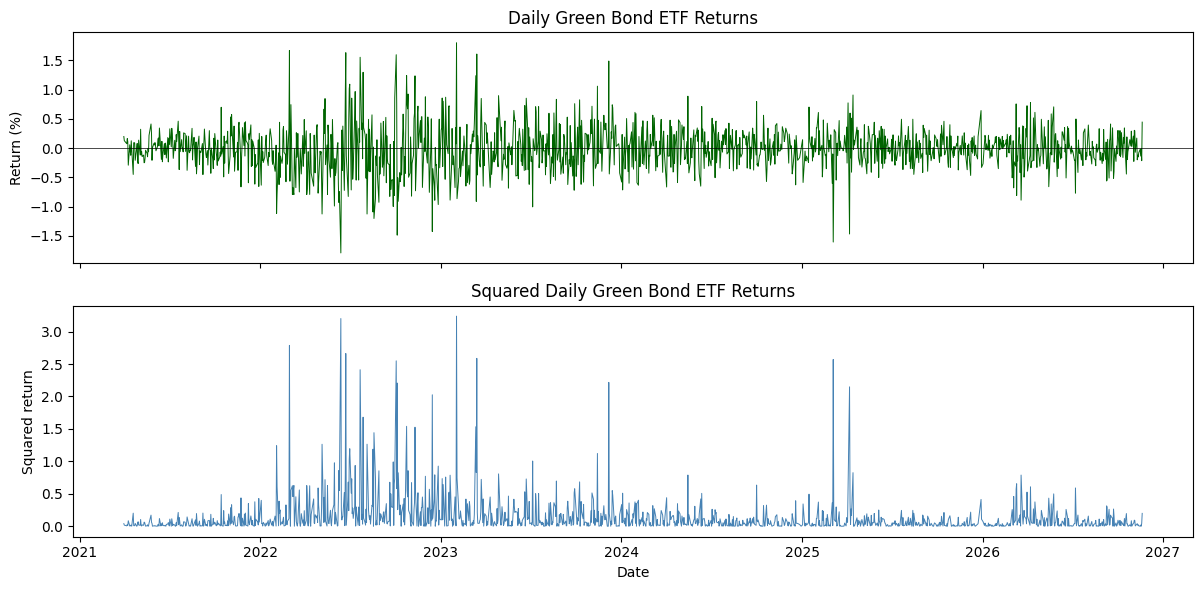

In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

returns = combined_corrected["Green_Bond_Return"]

axes[0].plot(returns, color="darkgreen", linewidth=0.7)
axes[0].set_title("Daily Green Bond ETF Returns")
axes[0].set_ylabel("Return (%)")
axes[0].axhline(0, color="black", linewidth=0.5)

axes[1].plot(returns**2, color="steelblue", linewidth=0.7)
axes[1].set_title("Squared Daily Green Bond ETF Returns")
axes[1].set_ylabel("Squared return")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.savefig("green_bond_returns.png", dpi=300, bbox_inches="tight")
plt.show()

In [39]:
from google.colab import files
files.download("green_bond_returns.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(
    combined_corrected["Green_Bond_Return"]
)

print("ADF Statistic:", round(adf_result[0], 4))
print("P-value:", adf_result[1])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(key, ":", round(value, 4))

ADF Statistic: -8.5187
P-value: 1.115777465545826e-13

Critical Values:
1% : -3.435
5% : -2.8636
10% : -2.5679


/tmp/ipykernel_1811/1605467811.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


In [41]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

train = combined_corrected.iloc[:1080]

X = sm.add_constant(train[
    ["Lag_Green_Return", "Lag_Gov_Return", "Lag_FX_Return"]
])

y = train["Green_Bond_Return"]

diagnostic_model = sm.OLS(y, X).fit()
residuals = diagnostic_model.resid

print("Ljung-Box Test:")
print(acorr_ljungbox(residuals, lags=[5, 10], return_df=True))

arch = het_arch(residuals, nlags=5)
print("\nARCH LM Statistic:", arch[0])
print("ARCH P-value:", arch[1])

jb = jarque_bera(residuals)
print("\nJarque-Bera Statistic:", jb[0])
print("Jarque-Bera P-value:", jb[1])

Ljung-Box Test:
      lb_stat  lb_pvalue
5    5.230282   0.388428
10  11.708525   0.305037

ARCH LM Statistic: 64.38342745958826
ARCH P-value: 1.5044268217255357e-12

Jarque-Bera Statistic: 207.52846207901916
Jarque-Bera P-value: 8.625157625895028e-46


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
